# Data

## 1. Source

**Food-101** (Bossard, Guillaumin & Van Gool, *"Food-101 – Mining Discriminative Components with Random Forests"*, ECCV 2014, ETH Zurich).

- **Origin:** photos uploaded by users to foodspotting.com; each image id is the foodspotting review id.
- **Size:** 101 food categories × 1,000 images = **101,000 JPEG images** (~5 GB).
- **Official split** (in `meta/`): 750 training and 250 test images per class, so 75,750 train and 25,250 test.
- **Labeling:** the authors **manually cleaned the test images**. They **intentionally left the training images uncleaned**, so they contain some noise: mostly very bright colors and occasionally wrong labels.
- **Preprocessing by the authors:** every image was rescaled so its longest side is at most 512 px.

### Files used
| File | Contents |
|---|---|
| `images/<class>/<id>.jpg` | the actual image data |
| `meta/train.txt`, `meta/test.txt` | one `class/id` per line, the official split |
| `meta/classes.txt`, `meta/labels.txt` | 101 folder names and their human-readable names |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
from pathlib import Path
from PIL import Image

import sys
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(REPO_ROOT))
from src.paths import FOOD101_DIR, CLEAN_INDEX

ROOT = FOOD101_DIR  # data/food-101, downloaded by `python -m src.data.download`

classes = (ROOT / 'meta' / 'classes.txt').read_text().split('\n')[:101]
names = (ROOT / 'meta' / 'labels.txt').read_text().split('\n')[:101]
class_to_name = dict(zip(classes, names))

frames = []
for split in ['train', 'test']:
    s = pd.read_csv(ROOT / 'meta' / f'{split}.txt', header=None, names=['id'])
    s['split'] = split
    frames.append(s)

df = pd.concat(frames, ignore_index=True)
df['label'] = df['id'].str.split('/').str[0]
df['name'] = df['label'].map(class_to_name)
df['path'] = df['id'].apply(lambda x: str(ROOT / 'images' / f'{x}.jpg'))
print(df.shape)
df.head()

(101000, 5)


,id,split,label,name,path
0,apple_pie/1005649,train,apple_pie,Apple pie,/Users/aravindbilugu/PycharmProjects/WelcomeSc...
1,apple_pie/1014775,train,apple_pie,Apple pie,/Users/aravindbilugu/PycharmProjects/WelcomeSc...
2,apple_pie/1026328,train,apple_pie,Apple pie,/Users/aravindbilugu/PycharmProjects/WelcomeSc...
3,apple_pie/1028787,train,apple_pie,Apple pie,/Users/aravindbilugu/PycharmProjects/WelcomeSc...
4,apple_pie/1043283,train,apple_pie,Apple pie,/Users/aravindbilugu/PycharmProjects/WelcomeSc...


## 2. Data quality evaluation

### 2a. Completeness and split integrity

In [2]:
print('Null values:\n', df.isna().sum(), '\n')
print('Duplicate ids:', df['id'].duplicated().sum())
print('Ids in both train and test:', len(set(df[df.split == 'train'].id) & set(df[df.split == 'test'].id)))

on_disk = {f'{p.parent.name}/{p.stem}' for p in (ROOT / 'images').glob('*/*.jpg')}
print('Images on disk:', len(on_disk))
print('Listed in meta but missing on disk:', len(set(df.id) - on_disk))
print('On disk but not in any split:', len(on_disk - set(df.id)))

Null values:
 id       0
split    0
label    0
name     0
path     0
dtype: int64 

Duplicate ids: 0
Ids in both train and test: 0


Images on disk: 101000
Listed in meta but missing on disk: 0
On disk but not in any split: 0


### 2b. Class balance

split   test  train
count  101.0  101.0
mean   250.0  750.0
std      0.0    0.0
min    250.0  750.0
25%    250.0  750.0
50%    250.0  750.0
75%    250.0  750.0
max    250.0  750.0


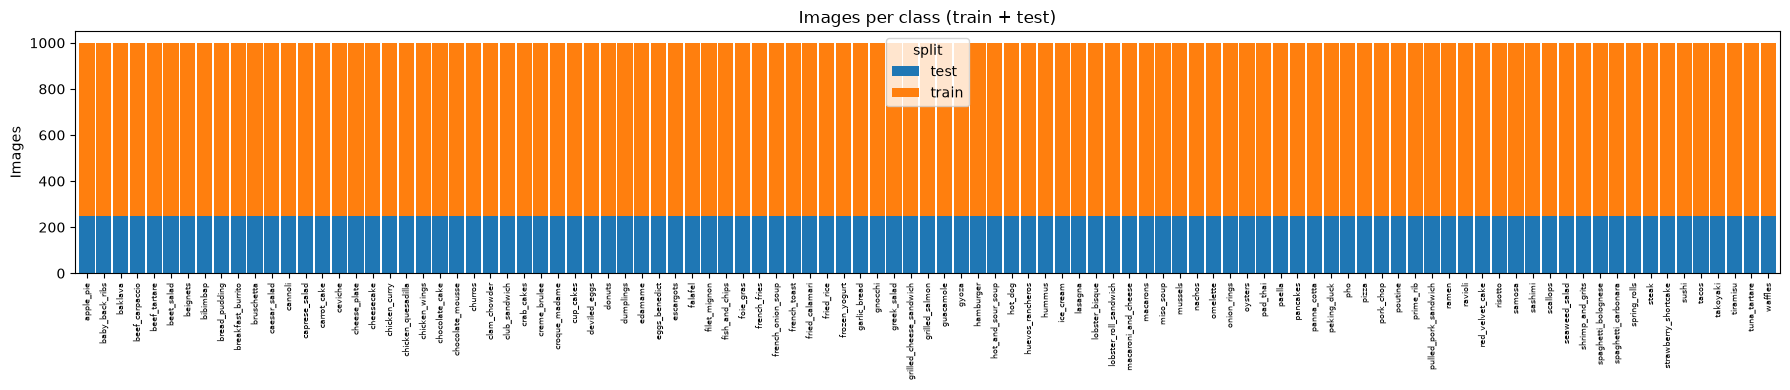

In [3]:
counts = df.groupby(['label', 'split']).size().unstack()
print(counts.describe())

fig, ax = plt.subplots(figsize=(18, 4))
counts.plot(kind='bar', stacked=True, ax=ax, width=0.9)
ax.set_title('Images per class (train + test)')
ax.set_xlabel('')
ax.set_ylabel('Images')
ax.tick_params(axis='x', labelsize=6)
plt.tight_layout()
plt.show()

### 2c. Image properties (engineered metadata features)

Each image's header gives its width, height and color mode, and the file system gives its file size. From these we derive **aspect ratio** and **megapixels**. This takes about a minute.

In [4]:
def image_meta(path):
    try:
        with Image.open(path) as im:
            return im.width, im.height, im.mode, False
    except Exception:
        return np.nan, np.nan, None, True

meta = df['path'].apply(image_meta)
df[['width', 'height', 'mode', 'corrupt']] = pd.DataFrame(meta.tolist(), index=df.index)
df['file_kb'] = df['path'].apply(lambda p: Path(p).stat().st_size / 1024)
df['aspect_ratio'] = df['width'] / df['height']
df['megapixels'] = df['width'] * df['height'] / 1e6

print('Corrupt / unreadable images:', df['corrupt'].sum())
print('\nColor modes:\n', df['mode'].value_counts())
print('\nLongest side == 512 px:', ((df[['width', 'height']].max(axis=1)) == 512).mean())
df[['width', 'height', 'aspect_ratio', 'megapixels', 'file_kb']].describe()

Corrupt / unreadable images: 0

Color modes:
 mode
RGB    100997
L           3
Name: count, dtype: int64

Longest side == 512 px: 1.0


,width,height,aspect_ratio,megapixels,file_kb
count,101000.000000,101000.000000,101000.000000,101000.000000,101000.000000
mean,495.791396,475.372129,1.071724,0.235092,49.472288
std,45.674348,65.305769,0.228205,0.036791,14.470559
min,193.000000,122.000000,0.376953,0.062464,8.489258
25%,512.000000,452.000000,1.000000,0.196608,39.786133
50%,512.000000,512.000000,1.000000,0.262144,48.423340
75%,512.000000,512.000000,1.132743,0.262144,57.134766
max,512.000000,512.000000,4.196721,0.262144,210.645508


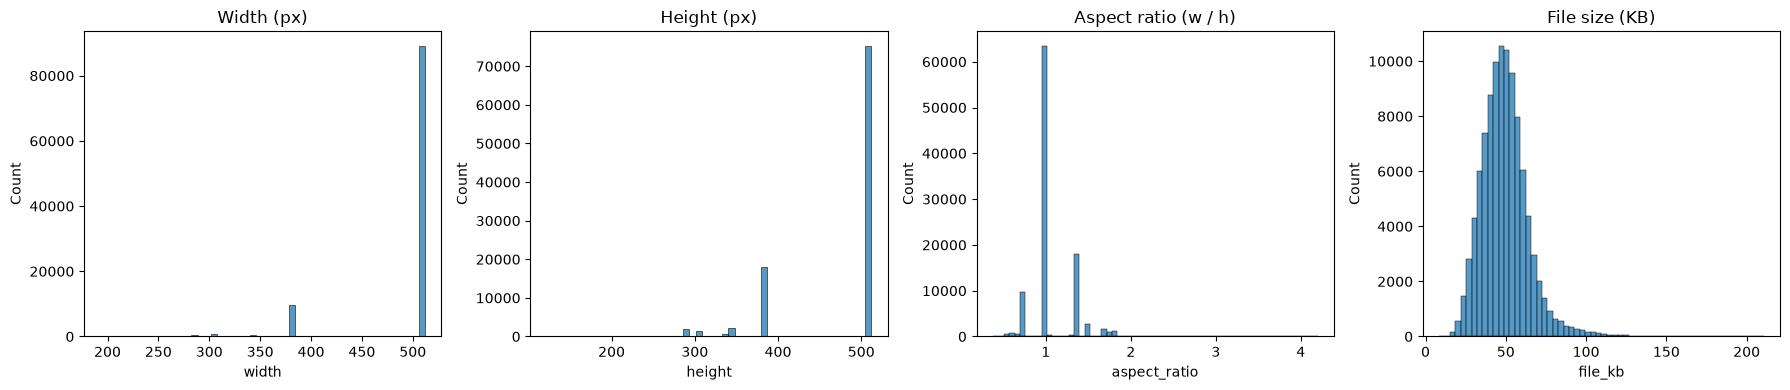

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.histplot(df['width'], bins=50, ax=axes[0]).set_title('Width (px)')
sns.histplot(df['height'], bins=50, ax=axes[1]).set_title('Height (px)')
sns.histplot(df['aspect_ratio'], bins=60, ax=axes[2]).set_title('Aspect ratio (w / h)')
sns.histplot(df['file_kb'], bins=60, ax=axes[3]).set_title('File size (KB)')
plt.tight_layout()
plt.show()

                          id  split mode  width  height
6104   bread_pudding/1375816  train    L    412     512
44856        lasagna/3787908  train    L    512     348
69802          steak/1340977  train    L    510     512

Extreme aspect ratio (>2 or <0.5): 44


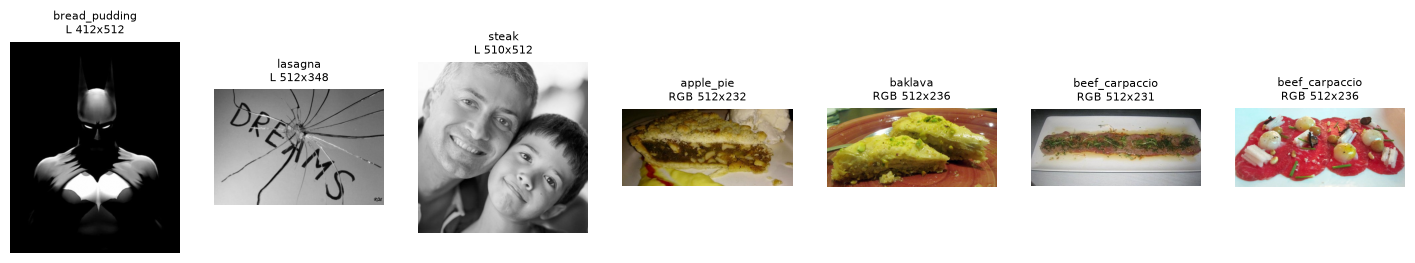

In [6]:
# Images that are not RGB (would break a 3-channel model input)
non_rgb = df[df['mode'] != 'RGB']
print(non_rgb[['id', 'split', 'mode', 'width', 'height']])

# Images with extreme aspect ratios (heavy distortion if naively resized to a square)
extreme = df[(df.aspect_ratio > 2) | (df.aspect_ratio < 0.5)]
print('\nExtreme aspect ratio (>2 or <0.5):', len(extreme))

fig, axes = plt.subplots(1, len(non_rgb) + 4, figsize=(18, 3))
for ax, (_, r) in zip(axes, pd.concat([non_rgb, extreme.head(4)]).iterrows()):
    ax.imshow(Image.open(r.path), cmap='gray')
    ax.set_title(f'{r.label}\n{r["mode"]} {int(r.width)}x{int(r.height)}', fontsize=8)
    ax.axis('off')
plt.show()

### 2d. Exact duplicate images

Two files with identical bytes (same MD5 hash) are the same photo. A duplicate that crosses the train/test boundary would **leak** test data into training. This takes 1–2 minutes.

In [7]:
df['md5'] = df['path'].apply(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())
dups = df[df.duplicated('md5', keep=False)].sort_values('md5')
print('Duplicate groups:', dups['md5'].nunique(), '| extra copies:', df.duplicated('md5').sum())
dups[['id', 'label', 'split', 'md5']]

Duplicate groups: 8 | extra copies: 8


,id,label,split,md5
17597,churros/2547960,churros,train,278e183b749e785827b393cbd56af2f1
81608,churros/2617186,churros,test,278e183b749e785827b393cbd56af2f1
50601,omelette/2619753,omelette,train,529006edf79da6cca279b64b0764fa46
54305,pancakes/2619752,pancakes,train,529006edf79da6cca279b64b0764fa46
56864,pho/51122,pho,train,536b8b434b21fcb49a79799bc9160a60
56913,pho/651427,pho,train,536b8b434b21fcb49a79799bc9160a60
56850,pho/4787,pho,train,6414c51bd7cfc963e374f68d95b41173
56863,pho/51112,pho,train,6414c51bd7cfc963e374f68d95b41173
24169,dumplings/167000,dumplings,train,8f517823504d1c01948433e0edac570f
24196,dumplings/180290,dumplings,train,8f517823504d1c01948433e0edac570f


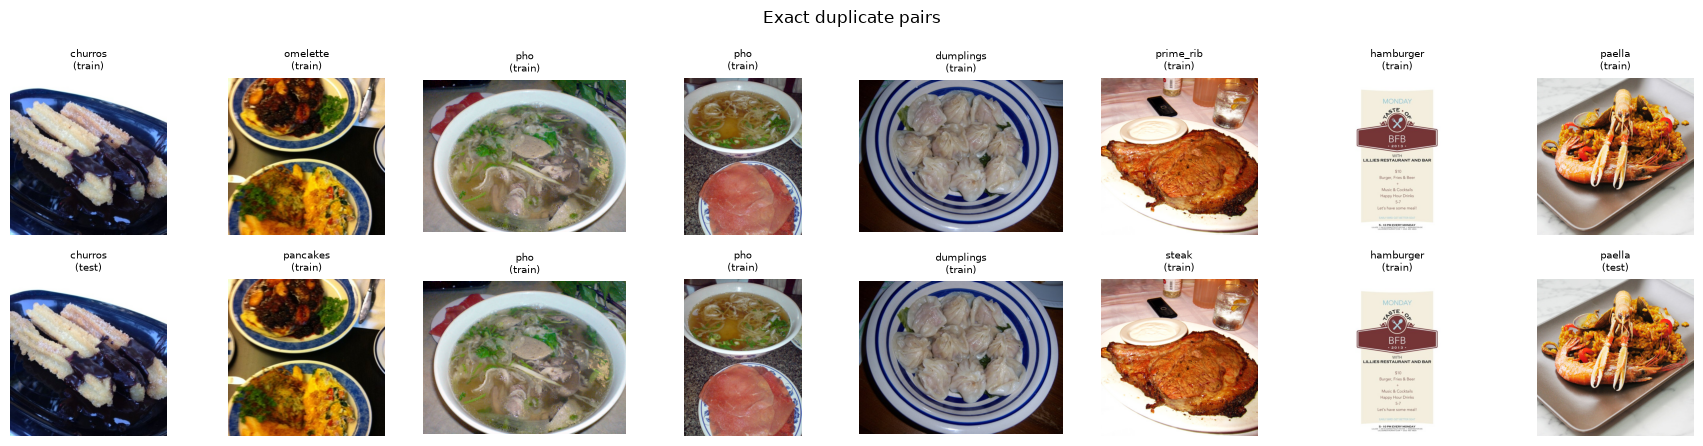

In [8]:
groups = list(dups.groupby('md5'))
fig, axes = plt.subplots(2, len(groups), figsize=(2.2 * len(groups), 4.5), squeeze=False)
for j, (_, g) in enumerate(groups):
    for i, (_, r) in enumerate(g.head(2).iterrows()):
        axes[i][j].imshow(Image.open(r.path))
        axes[i][j].set_title(f'{r.label}\n({r.split})', fontsize=7)
        axes[i][j].axis('off')
plt.suptitle('Exact duplicate pairs')
plt.tight_layout()
plt.show()

### 2e. Visual inspection: sample images

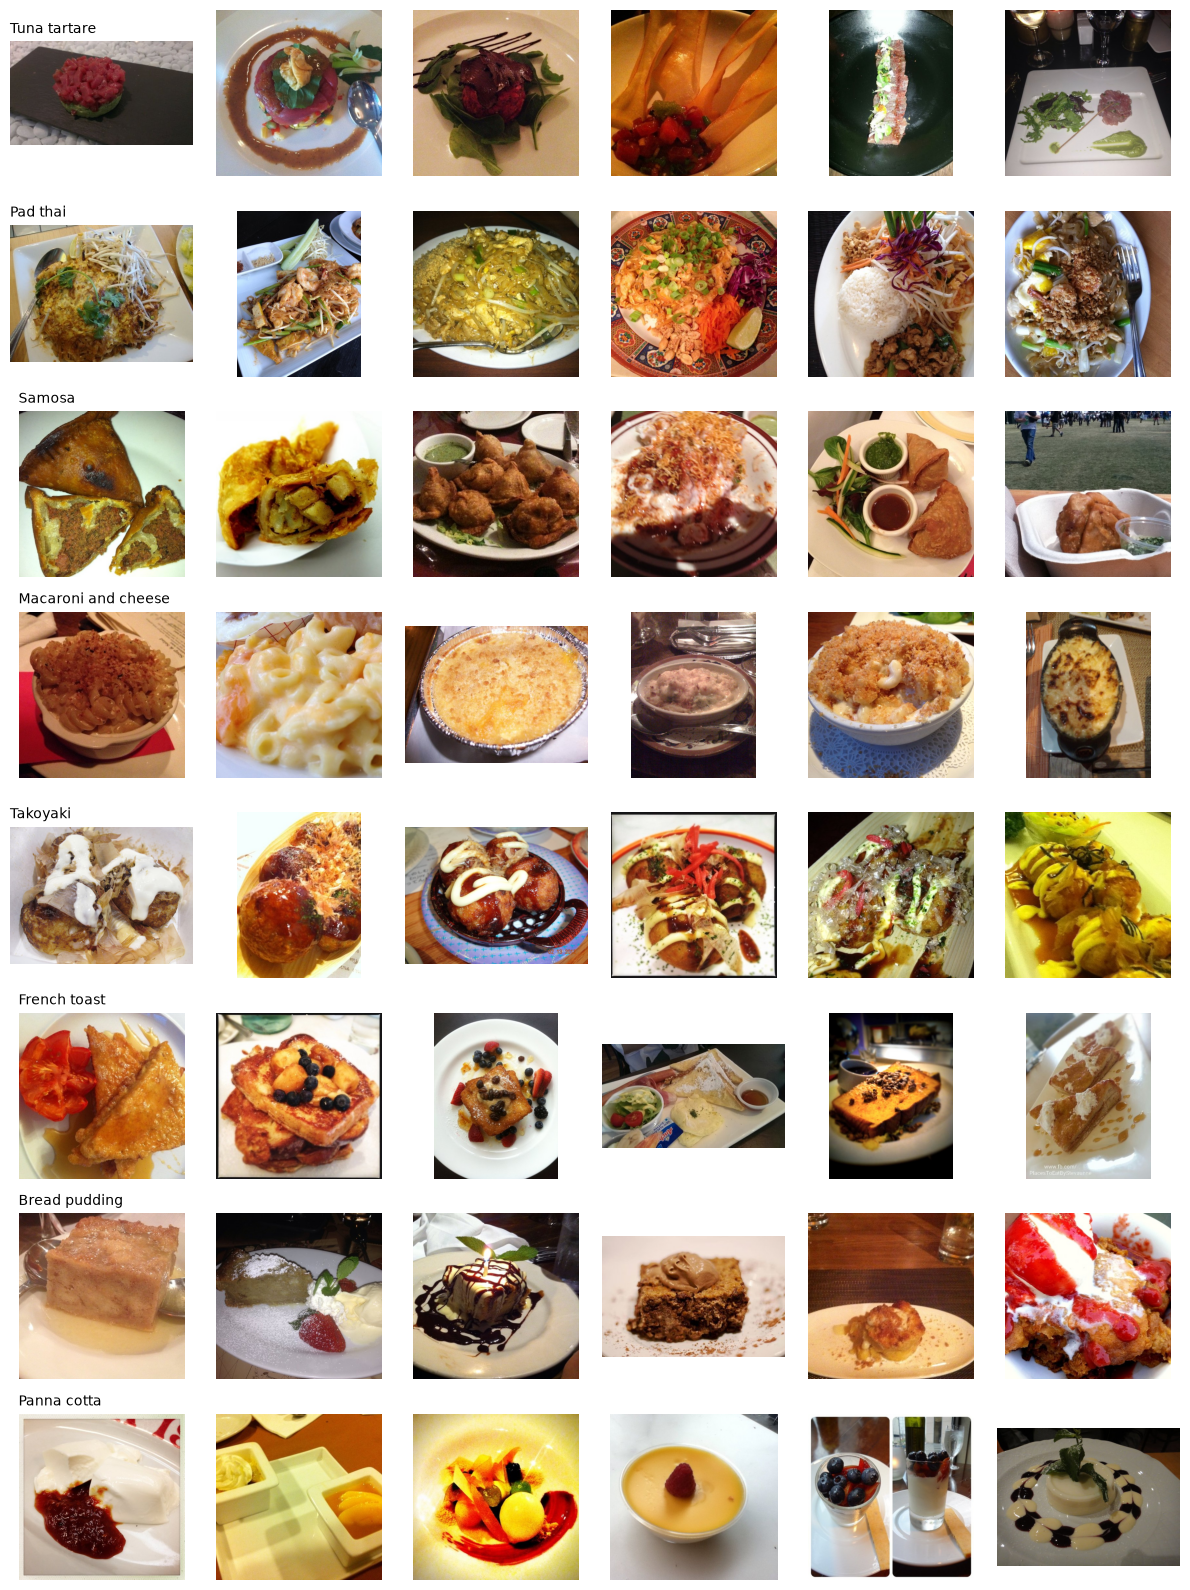

In [9]:
rng = np.random.default_rng(42)
sample_classes = rng.choice(classes, 8, replace=False)
fig, axes = plt.subplots(8, 6, figsize=(12, 16))
for i, c in enumerate(sample_classes):
    rows = df[(df.label == c) & (df.split == 'train')].sample(6, random_state=i)
    for j, (_, r) in enumerate(rows.iterrows()):
        axes[i][j].imshow(Image.open(r.path))
        axes[i][j].axis('off')
    axes[i][0].set_title(class_to_name[c], loc='left', fontsize=10)
plt.tight_layout()
plt.show()

### 2f. Color and brightness features

For a stratified sample of **20 training images per class**, each image is downsized to 64×64 and we compute its mean R, G and B values, its **brightness** (mean grayscale) and its **colorfulness** (mean saturation). These features show which classes are visually distinctive, and they help find the over-saturated or dark training images that the authors warned about.

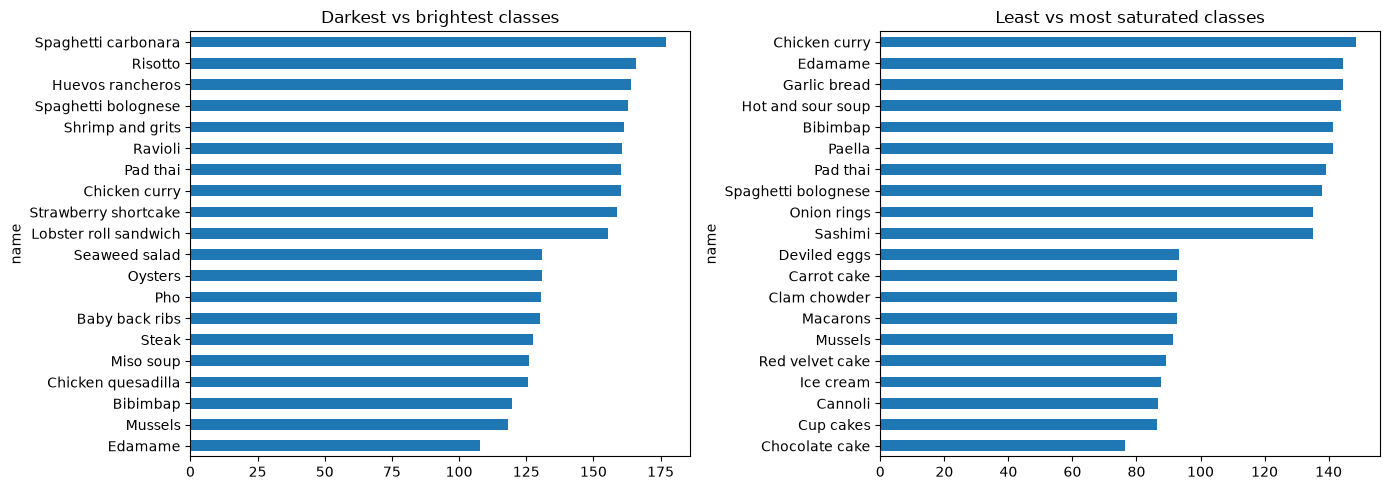

In [10]:
def color_features(path):
    im = Image.open(path).convert('RGB').resize((64, 64))
    rgb = np.asarray(im, dtype=np.float32)
    hsv = np.asarray(im.convert('HSV'), dtype=np.float32)
    return rgb[..., 0].mean(), rgb[..., 1].mean(), rgb[..., 2].mean(), hsv[..., 2].mean(), hsv[..., 1].mean()

sample = df[df.split == 'train'].groupby('label', group_keys=False).sample(20, random_state=0).copy()
sample[['mean_r', 'mean_g', 'mean_b', 'brightness', 'saturation']] = pd.DataFrame(
    sample['path'].apply(color_features).tolist(), index=sample.index)

by_class = sample.groupby('name')[['brightness', 'saturation']].mean().sort_values('brightness')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.concat([by_class.head(10), by_class.tail(10)])['brightness'].plot(kind='barh', ax=axes[0], title='Darkest vs brightest classes')
by_class.sort_values('saturation')['saturation'].iloc[np.r_[0:10, -10:0]].plot(kind='barh', ax=axes[1], title='Least vs most saturated classes')
plt.tight_layout()
plt.show()

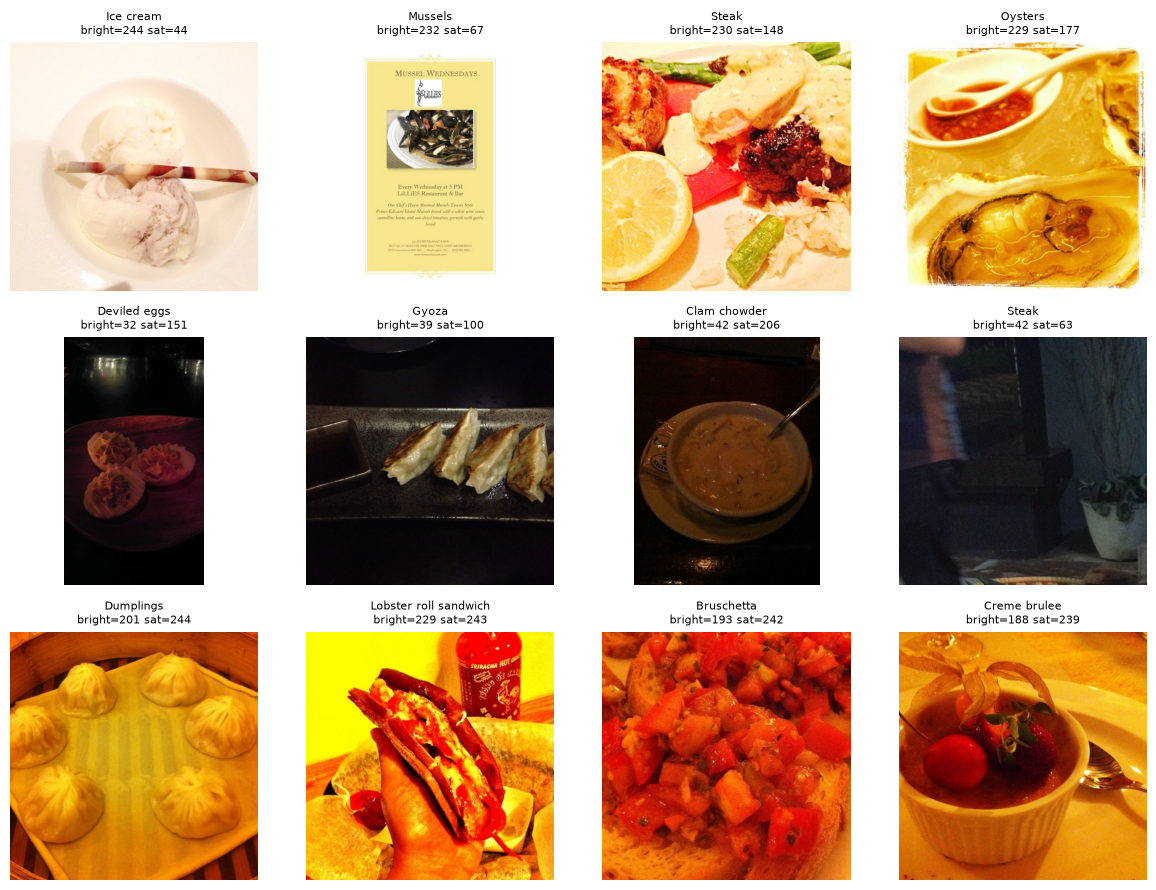

In [11]:
# Outliers: the most over-exposed, under-exposed and over-saturated training images in the sample
picks = pd.concat([sample.nlargest(4, 'brightness'), sample.nsmallest(4, 'brightness'), sample.nlargest(4, 'saturation')])
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, r) in zip(axes.ravel(), picks.iterrows()):
    ax.imshow(Image.open(r.path))
    ax.set_title(f'{r["name"]}\nbright={r.brightness:.0f} sat={r.saturation:.0f}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Summary of data quality

- **Complete:** all 101,000 listed images exist on disk and none are corrupt. No metadata values are missing.
- **Clean split:** no image id appears in both train and test.
- **Perfectly balanced:** each of the 101 classes has exactly 750 train and 250 test images, so no resampling or class weighting is needed.
- **Consistent resolution:** every image's longest side is exactly 512 px. Shapes vary: most are square or landscape (median aspect ratio 1.0, range ≈0.38–4.2), and a few are very small (minimum 193×122).
- **Color mode issues:** 3 images are grayscale (`L`) instead of RGB. On inspection, **none of them show food**: a Batman picture labeled *bread pudding*, a text image reading "DREAMS" labeled *lasagna*, and a family photo labeled *steak*. These are mislabeled, non-food images.
- **Exact duplicates:** 8 pairs of images are byte-for-byte identical:
  - **2 pairs leak across the split** (churros, paella): the same photo is in both train and test.
  - **2 pairs have conflicting labels**: the same photo is labeled *omelette* and *pancakes*, and another is labeled *prime rib* and *steak*. This is direct evidence of label noise in the training set.
  - 4 pairs are repeats within the same class (pho ×2, dumplings, hamburger). The *hamburger* pair is a restaurant flyer rather than a photo of food.
- **Label noise:** the training images were left uncleaned on purpose. The visual inspection and the brightness and saturation outliers show over-exposed or strongly filtered photos, and some images show several foods or contain non-food content. Because there are only ~1% of these, we keep them and rely on augmentation and the clean test set for an honest evaluation.
- **Visually similar classes:** some pairs (for example steak / filet mignon, pho / ramen, chocolate cake / chocolate mousse) are hard to tell apart even for humans, which limits the accuracy we can expect.

## 3. Transformations and engineered features

| Step | Why |
|---|---|
| Build one table from `train.txt` + `test.txt` with `split`, `label`, `name`, `path` | turns the folder-based dataset into a tabular index |
| **Label encoding**: `label_idx` = position of the class in `classes.txt` (0–100) | models need integer targets |
| **Metadata features**: `width`, `height`, `aspect_ratio`, `megapixels`, `file_kb`, `mode`, `md5` | used to evaluate quality (size, color mode, duplicates) |
| **Color features** (sample): `mean_r/g/b`, `brightness`, `saturation` | used to find exposure and color outliers and compare classes |
| **Remove duplicates**: drop the extra copy of each exact duplicate, keeping the test copy when a pair crosses splits | prevents train/test leakage |
| **Convert to RGB**: the 3 grayscale images are converted to 3 channels | a fixed input shape of 3 channels is required |
| **Validation split**: stratified 10% of train (75 per class) | lets us tune the model without touching the test set |
| **Image pipeline**: resize the shorter side to 256 → center crop 224×224 → scale to [0, 1] → normalize with ImageNet mean/std | sets a fixed input size, keeps the aspect ratio (no stretching), and matches pretrained CNNs |
| **Training augmentation**: random resized crop, horizontal flip, small color jitter | adds variety and makes the model less sensitive to the noisy and over-saturated training images |

In [12]:
# Label encoding
df['label_idx'] = df['label'].map({c: i for i, c in enumerate(classes)})

# Remove exact duplicates: rank test copies before train copies, keep the first one per hash
df['_order'] = (df['split'] == 'train').astype(int)
before = len(df)
df = df.sort_values(['md5', '_order']).drop_duplicates('md5', keep='first').drop(columns='_order').sort_index()
print('Removed duplicates:', before - len(df))

# Stratified validation split taken from the training set
val_idx = df[df.split == 'train'].groupby('label', group_keys=False).sample(frac=0.10, random_state=42).index
df.loc[val_idx, 'split'] = 'val'
print(df['split'].value_counts())

Removed duplicates: 8
split
train    68167
test     25250
val       7575
Name: count, dtype: int64


Output shape: (224, 224, 3) | mean per channel: [-1.53 -1.43 -1.2 ]


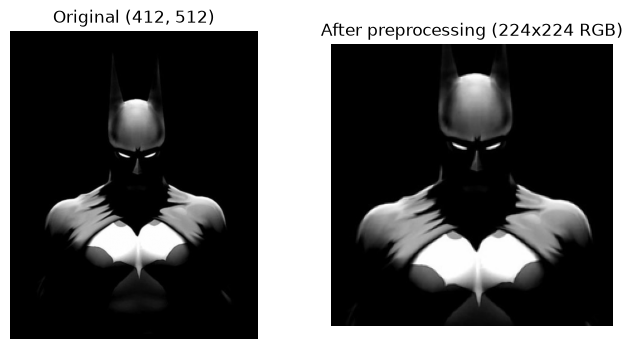

In [13]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

def preprocess(path, size=224, resize=256):
    im = Image.open(path).convert('RGB')                      # fixes the grayscale images
    scale = resize / min(im.size)                              # shorter side -> 256, aspect ratio kept
    im = im.resize((round(im.width * scale), round(im.height * scale)))
    left, top = (im.width - size) // 2, (im.height - size) // 2
    im = im.crop((left, top, left + size, top + size))         # center crop 224x224
    x = np.asarray(im, dtype=np.float32) / 255.0
    return (x - IMAGENET_MEAN) / IMAGENET_STD                  # shape (224, 224, 3)

r = df[df['mode'] == 'L'].iloc[0] if (df['mode'] == 'L').any() else df.iloc[0]
x = preprocess(r.path)
print('Output shape:', x.shape, '| mean per channel:', x.mean(axis=(0, 1)).round(2))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(Image.open(r.path), cmap='gray'); axes[0].set_title(f'Original {Image.open(r.path).size}')
axes[1].imshow(np.clip(x * IMAGENET_STD + IMAGENET_MEAN, 0, 1)); axes[1].set_title('After preprocessing (224x224 RGB)')
for a in axes: a.axis('off')
plt.show()

In [14]:
# Save the cleaned, feature-engineered index for the modeling notebook
out_cols = ['id', 'path', 'label', 'name', 'label_idx', 'split', 'width', 'height',
            'aspect_ratio', 'megapixels', 'file_kb', 'mode', 'md5']
clean = df[out_cols].copy()
# Store image paths relative to data/food-101 so the index works on any computer
clean['path'] = clean['path'].map(lambda p: Path(p).relative_to(ROOT).as_posix())
clean.to_csv(CLEAN_INDEX, index=False)
print('Saved', len(clean), 'rows to', CLEAN_INDEX.relative_to(REPO_ROOT))

Saved 100992 rows to data/food101_clean.csv
